# Microbe Classification

I compared Gaussian Naive Bayes, LDA, QDA, and a Bayes classifier with KDE on the included tabular dataset.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

#### Data Ingestion

In [17]:
dataset = pd.read_csv('microbes.csv')
dataset.rename(columns={'Unnamed: 0': 'Serial'}, inplace=True)
dataset.head(10)

,Serial,Solidity,Eccentricity,EquivDiameter,Extrema,FilledArea,Extent,Orientation,EulerNumber,BoundingBox1,...,ConvexHull4,MajorAxisLength,MinorAxisLength,Perimeter,ConvexArea,Centroid1,Centroid2,Area,raddi,microorganisms
0,0,10.70,15.8,5.43,3.75,0.785,8.14,2.1500,22.3,2.97,...,2.97,1.340,1.610,0.683,0.1950,3.63,12.10,1.310,7.99,Spirogyra
1,1,5.60,18.3,4.14,6.16,0.364,3.51,18.6000,22.5,5.41,...,5.47,1.520,1.520,1.010,0.2150,6.01,20.60,0.765,7.99,Spirogyra
2,2,8.32,19.8,4.63,6.66,0.415,5.85,21.0000,22.4,5.96,...,5.96,1.630,1.380,1.110,0.1820,6.55,11.50,0.953,7.99,Spirogyra
3,3,10.10,17.9,7.29,11.10,1.470,6.30,9.9400,21.9,8.81,...,8.88,2.040,2.120,0.715,0.3710,10.30,12.00,2.340,7.99,Spirogyra
4,4,6.27,20.2,20.10,10.70,14.700,3.97,2.5800,11.9,10.20,...,10.20,7.780,6.210,6.800,4.4400,14.00,9.55,17.600,7.99,Spirogyra
5,5,9.47,18.4,4.27,14.60,0.400,7.29,20.1000,22.5,13.60,...,13.60,1.080,1.070,0.963,0.1360,14.10,15.50,0.812,7.99,Spirogyra
6,6,13.50,19.8,4.50,17.30,0.493,9.67,0.0334,22.2,16.80,...,16.90,1.170,0.981,0.381,0.1070,17.20,7.88,0.903,7.99,Spirogyra
7,7,15.60,19.6,4.16,19.60,0.352,12.10,0.6270,22.3,19.30,...,19.30,0.979,0.845,0.328,0.0789,19.50,12.30,0.771,7.99,Spirogyra
8,8,8.95,20.0,8.59,3.28,1.520,5.50,9.0800,21.1,1.20,...,1.22,2.770,2.260,3.420,0.5760,3.32,11.60,3.240,9.69,Spirogyra
9,9,11.20,17.4,3.53,4.33,0.332,8.37,14.7000,22.6,3.60,...,3.60,0.896,0.966,0.347,0.0801,4.13,9.27,0.560,9.69,Spirogyra


#### Data Cleaning

In [18]:
num_missing_vals = dataset.isnull().sum().sum()
print(f"Number of missing values: {num_missing_vals}")

Number of missing values: 0


#### Split the Dataset

In [19]:
# column split
x_data = dataset.drop(columns=['Serial', 'microorganisms'])     # Serial is ID and microorganisms is target
x_data = x_data.iloc[:, :10]                                    # First ten features contain enough information
y_data = dataset['microorganisms']                              # Target variable

# train-test split
x_data, y_data = x_data.to_numpy(), y_data.to_numpy()
x_train, x_val, y_train, y_val = train_test_split(x_data, y_data, test_size=0.2, random_state=0, stratify=y_data)

#### Exploratory Analysis

<BarContainer object of 10 artists>

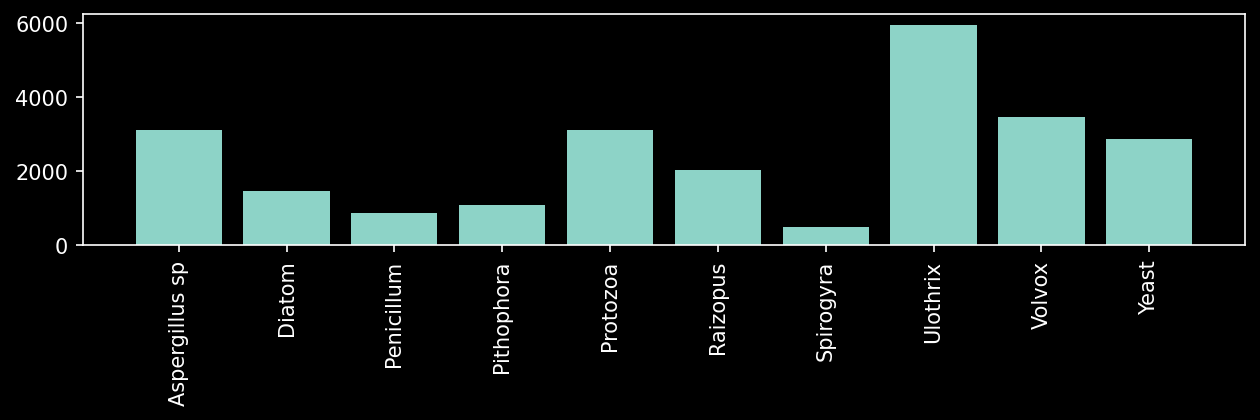

In [20]:
plt.style.use('dark_background')
plt.figure(figsize=(10, 2), dpi=150)
plt.xticks(rotation=90)
labels, counts = np.unique(y_train, return_counts=True)
plt.bar(labels, counts, align='center')

## Model Comparison

In [21]:
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import accuracy_score

from BayesClassifier import BayesClassifier
from KDEstimator import KDEstimator

### Gaussian Naive Bayes

In [22]:
# Initiate
gnb_model = BayesClassifier(mode='GNB')
# Fit
gnb_model.fit(x_train, y_train)
# Predict
gnb_y_pred = gnb_model.predict(x_val)
# Evalute
gnb_accuracy = gnb_model.score(x_val, y_val)
print("Gaussian Naive Bayes Accuracy:", gnb_accuracy)

Gaussian Naive Bayes Accuracy: 0.2601


#### Linear Discriminant Analysis

In [23]:
# Initiate
lda_model = BayesClassifier(mode='LDA')
# Fit
lda_model.fit(x_train, y_train)
# Predict
lda_y_pred = lda_model.predict(x_val)
# Evaluate
lda_accuracy = lda_model.score(x_val, y_val)
print("Linear Discriminant Analysis Accuracy:", lda_accuracy)

Linear Discriminant Analysis Accuracy: 0.3744


#### Quadratic Discriminant Analysis

In [24]:
qda_model = BayesClassifier(mode='QDA')
qda_model.fit(x_train, y_train)
qda_y_pred = qda_model.predict(x_val)
qda_accuracy = qda_model.score(x_val, y_val)
print("Quadratic Discriminant Analysis Accuracy:", qda_accuracy)

Quadratic Discriminant Analysis Accuracy: 0.3413


#### Kernel Density Estimation

In [25]:
kde_config = KDEstimator(bump='Gauss', bandwidth=0.5)
kde_model = BayesClassifier(mode='KDE', kde_config=kde_config)
kde_model.fit(x_train, y_train)
kde_y_pred = kde_model.predict(x_val)
kde_accuracy = kde_model.score(x_val, y_val)
print("Bayes Classifier with KDE Accuracy:", kde_accuracy)

Bayes Classifier with KDE Accuracy: 0.9767


KDE can represent class densities with shapes a single Gaussian cannot capture.

This KDE implementation evaluates kernels over the training points of each class during inference. The Gaussian models evaluate each class from its fitted parameters.

### Fixed Bandwidth Comparison

In [29]:
#Decreasing the bandwidth to 0.2 to see if it improves the accuracy
kde_config = KDEstimator(bump='Gauss', bandwidth=0.2)
kde_model = BayesClassifier(mode='KDE', kde_config=kde_config)
kde_model.fit(x_train, y_train)
kde_y_pred = kde_model.predict(x_val)
kde_accuracy = kde_model.score(x_val, y_val)
print("Bayes Classifier with KDE Accuracy:", kde_accuracy)

c:\Users\Youssef\Desktop\UNI\Pattern\Labs\Lab3\BayesClassifier.py:122: RuntimeWarning: invalid value encountered in divide
  return prob_product/np.sum(prob_product)


Bayes Classifier with KDE Accuracy: 0.9841
